# Model Development

## 1. Imports and Project Setup

This notebook develops predictive models to identify patients at risk of potential
statin discontinuation.

Two feature sets are evaluated:

- Model A: Early statin purchasing patterns.
- Model B: Purchasing patterns combined with demographic, insurance,
  healthcare utilization, and health-related characteristics.

Logistic regression and XGBoost are used to develop four candidate models.

This notebook focuses on data preparation, preprocessing, model training,
and saving the resulting model artifacts for subsequent evaluation.

In [2]:
import numpy as np
import pandas as pd

from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

# Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Models
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Evaluation utilities
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Model persistence
import joblib

RANDOM_STATE = 42

## 2. Load the Modeling Dataset

The modeling dataset is derived from the previously prepared baseline person-level dataset.

Each observation represents one individual. The dataset contains the outcome variable, demographic characteristics, healthcare utilization, insurance information, and statin purchasing information.

Two additional purchasing behavior features are engineered during this stage:

fill_change: Difference between statin purchases in Round 2 and Round 1.
single_fill: Binary indicator identifying individuals with exactly one statin purchase across Rounds 1 and 2.

The repository root is located dynamically to make the notebook easier to execute from different working directories.

In [4]:
# Find repository root
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "src" / "download_meps.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not find the repository root."
    )

print(f"Repository: {ROOT}")

Repository: C:\Users\chalv\statin-discontinuation


loading outputs

In [6]:
# baseline dataset
baseline = pd.read_csv(
    ROOT / "data" / "processed" / "baseline_person_dataset.csv",
    dtype={"DUPERSID": "string"}
)

# Change in statin purchases between rounds
baseline["fill_change"] = (
    baseline["statin_purchase_count_round_2"]
    - baseline["statin_purchase_count_round_1"]
)

# Exactly one statin purchase across both rounds
baseline["single_fill"] = (
    (
        baseline["statin_purchase_count_round_1"]
        + baseline["statin_purchase_count_round_2"]
    ) == 1
).astype(int)

# Organize datasets for inspection
datasets = {
    "Final baseline dataset": baseline,
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

# Verify one row per person
assert baseline["DUPERSID"].is_unique
assert baseline["DUPERSID"].notna().all()

# Verify engineered features
assert "fill_change" in baseline.columns
assert "single_fill" in baseline.columns

print("\nOne row per person confirmed.")
print("Engineered features successfully created.")

display(
    baseline[
        [
            "DUPERSID",
            "statin_purchase_count_round_1",
            "statin_purchase_count_round_2",
            "fill_change",
            "single_fill"
        ]
    ].head(10)
)

Final baseline dataset: (1339, 81)

One row per person confirmed.
Engineered features successfully created.


,DUPERSID,statin_purchase_count_round_1,statin_purchase_count_round_2,fill_change,single_fill
0,2790006101,0,2,2,0
1,2790011101,1,10,9,0
2,2790011102,0,11,11,0
3,2790021101,0,1,1,1
4,2790049101,1,2,1,0
5,2790050102,0,1,1,1
6,2790051101,0,2,2,0
7,2790063101,1,0,-1,1
8,2790063102,0,3,3,0
9,2790074101,1,1,0,0


## 3. Define the Prediction Outcome

The outcome variable is `discontinued`, a binary indicator representing
potential statin discontinuation.

- 0 = Continued statin purchasing
- 1 = Potential statin discontinuation

The outcome distribution is examined before modeling to identify
class imbalance and determine the appropriate training and evaluation
approach.

In [8]:
# Display all column names
for i, col in enumerate(baseline.columns):
    print(f"{i+1:02d}. {col}")

# Inspect data types
print("\nData types:")

# Inspect the first five records
display(baseline.head())

01. DUPERSID
02. discontinued
03. ALL5RDS_round_1
04. ALL5RDS_round_2
05. DIED_round_1
06. DIED_round_2
07. INST_round_1
08. INST_round_2
09. MILITARY_round_1
10. MILITARY_round_2
11. LEFTUS_round_1
12. LEFTUS_round_2
13. SEX_round_1
14. SEX_round_2
15. RACETHX_round_1
16. RACETHX_round_2
17. HISPANX_round_1
18. HISPANX_round_2
19. EDUCYR_round_1
20. EDUCYR_round_2
21. HIDEG_round_1
22. HIDEG_round_2
23. HWELLSPK_round_1
24. HWELLSPK_round_2
25. LONGWT_round_1
26. LONGWT_round_2
27. AGE_round_1
28. AGE_round_2
29. RTHLTH_round_1
30. RTHLTH_round_2
31. MNHLTH_round_1
32. MNHLTH_round_2
33. INS_round_1
34. INS_round_2
35. MCARE_round_1
36. MCARE_round_2
37. MCAID_round_1
38. MCAID_round_2
39. PRIVAT_round_1
40. PRIVAT_round_2
41. PMEDIN_round_1
42. PMEDIN_round_2
43. ELGRND_round_1
44. ELGRND_round_2
45. INSCOP_round_1
46. INSCOP_round_2
47. BEGRFM_round_1
48. BEGRFM_round_2
49. BEGRFY_round_1
50. BEGRFY_round_2
51. ENDRFM_round_1
52. ENDRFM_round_2
53. ENDRFY_round_1
54. ENDRFY_round_2


,DUPERSID,discontinued,ALL5RDS_round_1,ALL5RDS_round_2,DIED_round_1,DIED_round_2,INST_round_1,INST_round_2,MILITARY_round_1,MILITARY_round_2,...,active_condition_count_round_2,new_condition_count_round_1,new_condition_count_round_2,active_icd10_codes_round_1,active_icd10_codes_round_2,active_ccsr_codes_round_1,active_ccsr_codes_round_2,statin_rx_cost_baseline_total,fill_change,single_fill
0,2790006101,0,1,1,0,0,0,0,0,0,...,4,2,0,C50; E03,C50; E03; E11; E78,END001; NEO030,END001; END002; END005; END010; NEO030,18.00,2,0
1,2790011101,0,1,1,0,0,0,0,0,0,...,1,1,0,E78,E78,END010,END010,110.00,9,0
2,2790011102,0,1,1,0,0,0,0,0,0,...,7,3,4,I10; M79; S82,E78; I10; M79; S82,CIR007; INJ042; MUS025,CIR007; END010; INJ000; INJ042; MUS025; RSP000...,72.46,11,0
3,2790021101,0,1,1,0,0,0,0,0,0,...,3,1,1,E11,E11; E78; M10,END002; END005,END002; END005; END010; MUS033,0.00,1,1
4,2790049101,0,1,1,0,0,0,0,0,0,...,5,3,2,E78; H40; Z96,E78; H40; M25; M48; Z96,END010; EYE003; FAC009,END010; EYE003; FAC009; MUS010; MUS011,47.21,1,0


In [9]:
# Outcome/label columns
outcome_candidates = [
    col for col in baseline.columns
    if any(word in col.lower()
           for word in ["outcome", "discontinu", "label", "target", "continued"])
]

print(outcome_candidates)

['discontinued']


In [10]:
TARGET = "discontinued"

# Check outcome distribution
print(baseline[TARGET].value_counts(dropna=False))

print("\nOutcome proportions:")
print(baseline[TARGET].value_counts(normalize=True))

# Confirm binary outcome
assert baseline[TARGET].notna().all()
assert set(baseline[TARGET].unique()).issubset({0, 1})

# Confirm cohort size
print("\nTotal patients:", len(baseline))
print("Potential discontinuation:", (baseline[TARGET] == 1).sum())
print("Continued purchases:", (baseline[TARGET] == 0).sum())

discontinued
0    1232
1     107
Name: count, dtype: int64

Outcome proportions:
discontinued
0    0.92009
1    0.07991
Name: proportion, dtype: float64

Total patients: 1339
Potential discontinuation: 107
Continued purchases: 1232


The dataset contains 1,339 individuals, of whom 107 (8.0%) are classified
as potentially discontinuing statin purchases. The remaining 1,232
individuals (92.0%) continued purchasing.

## 4. Define Candidate Feature Sets

Two feature sets are developed to examine whether demographic and
healthcare characteristics improve the prediction of potential
statin discontinuation beyond early purchasing behavior.

### Model A: Purchase-Only Features

This model uses early statin purchasing patterns, including purchase
frequency and prescription costs.

The purpose is to determine whether purchasing behavior alone provides
useful predictive information.

### Model B: Comprehensive Features

This model incorporates the purchase-only variables and additional
patient characteristics, including demographics, insurance coverage,
health status, healthcare utilization, and existing health conditions.

The purpose is to determine whether incorporating broader patient
characteristics improves predictive performance.

In [13]:
# Model A: Purchase only features
purchase_features = [
    "statin_purchase_count_round_1",
    "statin_purchase_count_round_2",
    "statin_rx_cost_round_1",
    "statin_rx_cost_round_2",
    "statin_rx_cost_baseline_total",
    "fill_change",
    "single_fill"
]

Model B: Comprehensive Features

In [15]:
# Model B: Comprehensive Patient Characteristics
additional_features = [

    # Demographics
    "AGE_round_1",
    "SEX_round_1",
    "RACETHX_round_1",
    "HISPANX_round_1",
    "EDUCYR_round_1",
    "HIDEG_round_1",

    # Self-reported health
    "RTHLTH_round_1",
    "MNHLTH_round_1",
    "HWELLSPK_round_1",

    # Insurance
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1",

    # Healthcare utilization
    "rx_purchase_count_round_1",
    "rx_purchase_count_round_2",
    "distinct_drug_count_round_1",
    "distinct_drug_count_round_2",

    # Health conditions
    "active_condition_count_round_1",
    "active_condition_count_round_2"

]

Comprehensive Feature Set

In [17]:
# Comprehensive Feature Set
TARGET = "discontinued"

purchase_features = [
    "statin_purchase_count_round_1",
    "statin_purchase_count_round_2",
    "statin_rx_cost_round_1",
    "statin_rx_cost_round_2",
    "statin_rx_cost_baseline_total",
    "fill_change",
    "single_fill"
]

additional_features = [
    "AGE_round_1",
    "SEX_round_1",
    "RACETHX_round_1",
    "HISPANX_round_1",
    "EDUCYR_round_1",
    "HIDEG_round_1",
    "RTHLTH_round_1",
    "MNHLTH_round_1",
    "HWELLSPK_round_1",
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1",
    "rx_purchase_count_round_1",
    "rx_purchase_count_round_2",
    "distinct_drug_count_round_1",
    "distinct_drug_count_round_2",
    "active_condition_count_round_1",
    "active_condition_count_round_2",
]

full_features = purchase_features + additional_features

print("Purchase-only features:", len(purchase_features))
print("Additional features:", len(additional_features))
print("Full feature set:", len(full_features))

# Validate column names
assert set(full_features).issubset(baseline.columns)

print("\nAll feature columns exist.")

Purchase-only features: 7
Additional features: 20
Full feature set: 27

All feature columns exist.


## 5. Clean Special MEPS Values

MEPS variables may contain special numeric codes representing
nonresponse or other unavailable information.

These codes should not automatically be interpreted as valid numerical
measurements.

For the selected education and self-reported health variables, codes
-7 and -8 are treated as missing values.

Missing values will subsequently be handled through the preprocessing
pipelines using imputation.

In [19]:
categorical_features = [
    "SEX_round_1",
    "RACETHX_round_1",
    "HISPANX_round_1",
    "EDUCYR_round_1",
    "HIDEG_round_1",
    "RTHLTH_round_1",
    "MNHLTH_round_1",
    "HWELLSPK_round_1",
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1"
]

for col in categorical_features:
    print(f"\n{col}")
    print(baseline[col].value_counts(dropna=False).sort_index())


SEX_round_1
SEX_round_1
1    657
2    682
Name: count, dtype: int64

RACETHX_round_1
RACETHX_round_1
1    193
2    896
3    170
4     50
5     30
Name: count, dtype: int64

HISPANX_round_1
HISPANX_round_1
1     193
2    1146
Name: count, dtype: int64

EDUCYR_round_1
EDUCYR_round_1
-8       5
-7       1
 0       4
 1       4
 2       6
 3      11
 4      10
 5       5
 6      29
 7      12
 8      29
 9      33
 10     40
 11     41
 12    407
 13     96
 14    151
 15     32
 16    230
 17    193
Name: count, dtype: int64

HIDEG_round_1
HIDEG_round_1
-8      6
-7      1
 1    185
 2     74
 3    519
 4    239
 5    146
 6     35
 7    134
Name: count, dtype: int64

RTHLTH_round_1
RTHLTH_round_1
-7      1
 1    161
 2    432
 3    427
 4    228
 5     90
Name: count, dtype: int64

MNHLTH_round_1
MNHLTH_round_1
-7      1
 1    348
 2    414
 3    409
 4    143
 5     24
Name: count, dtype: int64

HWELLSPK_round_1
HWELLSPK_round_1
-1    1092
 1     105
 2      61
 3      43
 4      38
Na

Cleaning the special values

In [21]:
# Make a copy so the original dataset stays unchanged
model_data = baseline.copy()

# Variables where negative codes represent nonresponse
missing_code_variables = [
    "EDUCYR_round_1",
    "HIDEG_round_1",
    "RTHLTH_round_1",
    "MNHLTH_round_1"
]

# Replace documented special values with NaN
for col in missing_code_variables:
    model_data[col] = model_data[col].replace({
        -7: np.nan,
        -8: np.nan
    })

# Exclude HWELLSPK pending codebook verification
additional_features.remove("HWELLSPK_round_1")

# Rebuild comprehensive feature set
full_features = purchase_features + additional_features

print("Purchase features:", len(purchase_features))
print("Additional features:", len(additional_features))
print("Full features:", len(full_features))

print("\nMissing values after cleaning:")
display(
    model_data[full_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Purchase features: 7
Additional features: 19
Full features: 26

Missing values after cleaning:


HIDEG_round_1                     7
EDUCYR_round_1                    6
RTHLTH_round_1                    1
MNHLTH_round_1                    1
active_condition_count_round_1    0
distinct_drug_count_round_2       0
distinct_drug_count_round_1       0
rx_purchase_count_round_2         0
rx_purchase_count_round_1         0
PMEDIN_round_1                    0
dtype: int64

## 6. Identify Numerical and Categorical Features

The selected predictors are divided into numerical and categorical
variables to support appropriate preprocessing.

Numerical variables include age, purchasing counts, prescription costs,
and healthcare utilization counts.

Categorical variables include demographic, insurance, education,
and self-reported health characteristics.

Categorical variables will be one-hot encoded, while numerical variables
will be imputed and standardized.

In [23]:
categorical_features = [
    "SEX_round_1",
    "RACETHX_round_1",
    "HISPANX_round_1",
    "EDUCYR_round_1",
    "HIDEG_round_1",
    "RTHLTH_round_1",
    "MNHLTH_round_1",
    "INS_round_1",
    "MCARE_round_1",
    "MCAID_round_1",
    "PRIVAT_round_1",
    "PMEDIN_round_1"
]

numerical_features = [
    col for col in full_features
    if col not in categorical_features
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['statin_purchase_count_round_1', 'statin_purchase_count_round_2', 'statin_rx_cost_round_1', 'statin_rx_cost_round_2', 'statin_rx_cost_baseline_total', 'fill_change', 'single_fill', 'AGE_round_1', 'rx_purchase_count_round_1', 'rx_purchase_count_round_2', 'distinct_drug_count_round_1', 'distinct_drug_count_round_2', 'active_condition_count_round_1', 'active_condition_count_round_2']

Categorical features:
['SEX_round_1', 'RACETHX_round_1', 'HISPANX_round_1', 'EDUCYR_round_1', 'HIDEG_round_1', 'RTHLTH_round_1', 'MNHLTH_round_1', 'INS_round_1', 'MCARE_round_1', 'MCAID_round_1', 'PRIVAT_round_1', 'PMEDIN_round_1']


## 7. Create Training and Test Sets

The dataset is divided into training and testing subsets using an
80/20 split.

Stratification is applied to preserve the proportion of individuals
classified as potentially discontinuing statin purchases in both subsets.

The same split is used for both candidate feature sets to ensure
a fair comparison between models.

The patient identifier is not included as a predictor.

## Preserving DUPERSID in the saved data splits

In [26]:
# Preserve patient identifiers
ids = model_data["DUPERSID"].copy()

# Predictors and outcome
X = model_data[full_features].copy()
y = model_data[TARGET].astype(int)

# Split predictors, outcomes, and identifiers together
X_train, X_test, y_train, y_test, ids_train, ids_test = (
    train_test_split(
        X,
        y,
        ids,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("Training IDs:", len(ids_train))
print("Testing IDs:", len(ids_test))

# Verify alignment
assert X_train.index.equals(y_train.index)
assert X_train.index.equals(ids_train.index)

assert X_test.index.equals(y_test.index)
assert X_test.index.equals(ids_test.index)

assert ids_train.is_unique
assert ids_test.is_unique
assert set(ids_train).isdisjoint(set(ids_test))

print("\nPatient identifiers successfully aligned.")


Training observations: 1071
Testing observations: 268
Training IDs: 1071
Testing IDs: 268

Patient identifiers successfully aligned.


In [27]:
TARGET = "discontinued"

X = model_data[full_features].copy()
y = model_data[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining outcome distribution:")
print(y_train.value_counts())

print("\nTesting outcome distribution:")
print(y_test.value_counts())

# Confirm new features are included in both datasets
assert "fill_change" in X_train.columns
assert "single_fill" in X_train.columns

assert X_train.shape[1] == 26
assert X_test.shape[1] == 26

print("\nAll 26 features successfully included.")

Training observations: 1071
Testing observations: 268

Training outcome distribution:
discontinued
0    985
1     86
Name: count, dtype: int64

Testing outcome distribution:
discontinued
0    247
1     21
Name: count, dtype: int64

All 26 features successfully included.


## 8. Build Preprocessing Pipelines

Preprocessing is performed within scikit-learn pipelines to ensure
that transformations are learned from the training data only.

Two preprocessing operations are applied:

### Numerical variables
- Missing values are replaced using the training-set median.
- Variables are standardized using StandardScaler.

### Categorical variables
- Missing values are replaced using the most frequent training-set value.
- Categories are converted into binary indicators using OneHotEncoder.

The preprocessing pipelines are fitted separately for each feature
set and incorporated into the candidate models.

In [29]:
#from sklearn.pipeline import Pipeline
#from sklearn.compose import ColumnTransformer
#from sklearn.impute import SimpleImputer
#from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

### 9. Define the Candidate Models

Four predictive models are developed to compare the predictive value of early statin purchasing patterns against a more comprehensive set of patient characteristics.

Two classification algorithms are evaluated:

Logistic Regression: Serves as the baseline model and provides a relatively interpretable approach to binary classification.
XGBoost: Provides a more flexible, tree-based approach capable of capturing nonlinear relationships and interactions between predictors.

Each algorithm is evaluated using two feature sets:

Model A – Purchase Only: Includes seven statin purchasing variables, including purchase counts, prescription costs, fill_change, and single_fill.
Model B – Comprehensive Features: Includes the seven purchase-only variables and 19 additional demographic, health, insurance, and healthcare utilization characteristics, for a total of 26 predictors.

Each model incorporates its own preprocessing pipeline. This ensures that numerical imputation, standardization, and categorical encoding are performed consistently within the model training process.

The resulting four models allow for comparisons between algorithms and feature sets.

In [31]:
def create_preprocessor(features):

    # Identify numerical and categorical predictors
    numeric_cols = [
        col for col in features
        if col in numerical_features
    ]

    categorical_cols = [
        col for col in features
        if col in categorical_features
    ]

    # Numerical preprocessing
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical preprocessing
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Combine preprocessing steps
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_cols),
            ("cat", categorical_transformer, categorical_cols)
        ]
    )

    return preprocessor

### 10. Create the Modeling Functions

Reusable modeling functions are created to maintain consistency across the four candidate models.

Each function combines the appropriate preprocessing pipeline with its classification algorithm.

Logistic regression is configured with an increased iteration limit to support model convergence. XGBoost is configured with a relatively shallow tree depth, a lower learning rate, and regularization parameters to help control model complexity.

Using these functions allows the same modeling configurations to be applied to both feature sets.

In [33]:
def create_logistic_model(features):

    return Pipeline(steps=[
        ("preprocessor", create_preprocessor(features)),
        ("classifier", LogisticRegression(
            max_iter=3000,
            C=1.0,
            random_state=42
        ))
    ])

In [34]:
def create_xgb_model(features):

    return Pipeline(steps=[
        ("preprocessor", create_preprocessor(features)),
        ("classifier", XGBClassifier(
            n_estimators=150,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=5,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])

### 11. Define the Four Candidate Models
Four candidate models are established using the two classification algorithms and two feature sets.


The models are Logistic Regression – Purchase Only, XGBoost – Purchase Only, Logistic Regression – Comprehensive Features, XGBoost – Comprehensive Features.


All four models use the same training and test observations, allowing their predictive performance to be compared under consistent conditions.


The models will first be evaluated using five-fold stratified cross-validation on the training dataset. The held-out test dataset will be reserved for subsequent final evaluation.





In [36]:
models = {
    "Logistic - Purchase Only":
        (create_logistic_model(purchase_features),
         purchase_features),

    "XGBoost - Purchase Only":
        (create_xgb_model(purchase_features),
         purchase_features),

    "Logistic - Full Features":
        (create_logistic_model(full_features),
         full_features),

    "XGBoost - Full Features":
        (create_xgb_model(full_features),
         full_features)
}

print("Four models successfully defined.")

Four models successfully defined.


### 12. Five-Fold Stratified Cross-Validation

Five-fold stratified cross-validation is used to evaluate the four candidate models using the training dataset.

The training data are divided into five approximately equal folds. Each model is trained five times, with four folds used for training and the remaining fold used for validation. Each fold serves as the validation set once.

Stratification preserves the proportion of individuals with and without potential statin discontinuation across the folds. This is particularly important because the outcome is imbalanced, with approximately 8% of individuals classified as having potential discontinuation.

Two performance metrics are calculated for each validation fold:

Area Under the Receiver Operating Characteristic Curve (AUROC): Measures the model's ability to distinguish between individuals with and without potential discontinuation. Higher values indicate better discrimination.
Average Precision (PR-AUC): Summarizes precision across different recall levels and is particularly useful when evaluating imbalanced outcomes.

The mean and standard deviation of each metric are calculated across the five folds. These results are used to compare the predictive performance and consistency of the four candidate models.

In [38]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, (model, features) in models.items():

    X_cv = X_train[features]

    fold_auroc = []
    fold_ap = []

    for train_idx, val_idx in cv.split(X_cv, y_train):

        X_fold_train = X_cv.iloc[train_idx]
        X_fold_val = X_cv.iloc[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Fit model
        model.fit(X_fold_train, y_fold_train)

        # Predicted probabilities
        probabilities = model.predict_proba(
            X_fold_val
        )[:, 1]

        # Evaluation
        fold_auroc.append(
            roc_auc_score(y_fold_val, probabilities)
        )

        fold_ap.append(
            average_precision_score(
                y_fold_val, probabilities
            )
        )

    cv_results.append({
        "Model": name,
        "Mean AUROC": np.mean(fold_auroc),
        "SD AUROC": np.std(fold_auroc),
        "Mean Average Precision": np.mean(fold_ap),
        "SD Average Precision": np.std(fold_ap)
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.round(4)
)

,Model,Mean AUROC,SD AUROC,Mean Average Precision,SD Average Precision
0,Logistic - Purchase Only,0.5551,0.0835,0.1289,0.0224
1,XGBoost - Purchase Only,0.6336,0.0420,0.1253,0.0120
2,Logistic - Full Features,0.6297,0.0411,0.1598,0.0245
3,XGBoost - Full Features,0.6614,0.0434,0.2505,0.0405


Visualize cross-validation performance

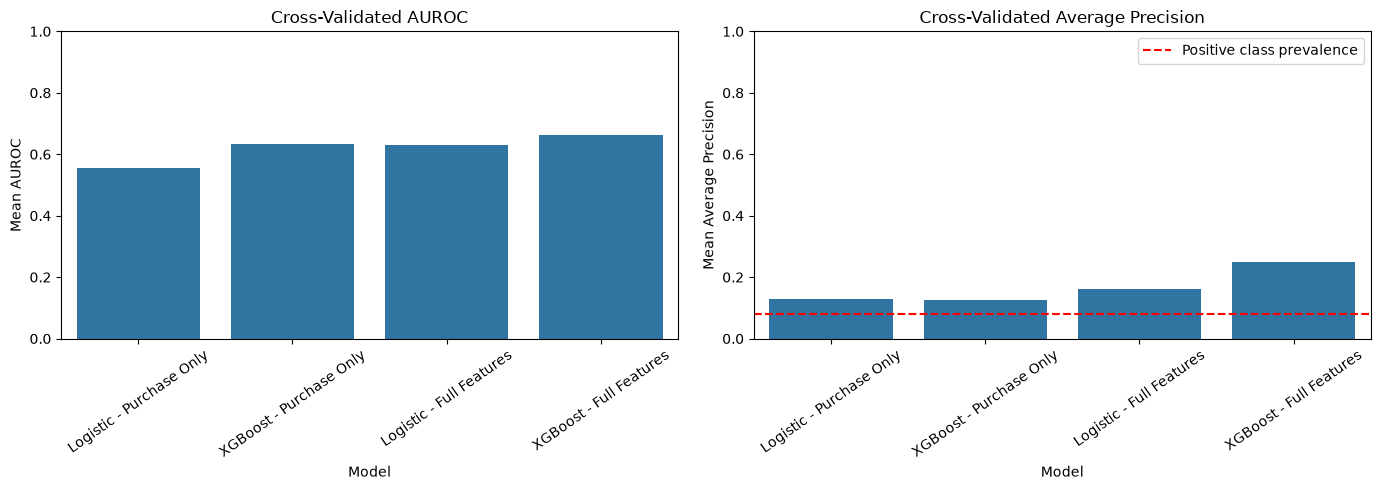

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# AUROC comparison
sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Mean AUROC",
    ax=axes[0]
)

axes[0].set_title("Cross-Validated AUROC")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=35)

# Average Precision comparison
sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Mean Average Precision",
    ax=axes[1]
)

axes[1].set_title("Cross-Validated Average Precision")
axes[1].set_ylim(0, 1)

# Add baseline for random ranking
axes[1].axhline(
    y=y_train.mean(),
    color="red",
    linestyle="--",
    label="Positive class prevalence"
)

axes[1].legend()
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

### Summary

Four predictive models were evaluated using five-fold stratified cross-validation: logistic regression and XGBoost, each trained using either early statin purchasing patterns alone or a comprehensive feature set.

The full-feature XGBoost model achieved the highest mean AUROC (0.6614) and mean Average Precision (0.2505).

The full-feature logistic regression model achieved a mean AUROC of 0.6297 and mean Average Precision of 0.1598.

The purchase-only models demonstrated comparatively limited predictive performance. Logistic regression achieved a mean AUROC of 0.5551, while XGBoost achieved 0.6336.

These preliminary results suggest that incorporating demographic, insurance, healthcare utilization, and health-related characteristics alongside early statin purchasing behavior may improve predictive performance.

The full-feature XGBoost model is selected as the leading candidate for subsequent evaluation, while logistic regression is retained as the interpretable baseline.

Final conclusions will depend on performance using the held-out test dataset, including discrimination, precision-recall performance, calibration, and subgroup evaluation.

### 13. Fit Final Candidate Models

Following cross-validation, all four candidate models are fitted using the complete training dataset.

Each model retains its previously defined preprocessing pipeline and classification algorithm. The models are trained using the same training observations to maintain consistency across comparisons.

The held-out test dataset is not used during model fitting. It is reserved for independent evaluation in the subsequent notebook.

The fitted models and their corresponding feature sets are retained for use in the evaluation stage.

In [43]:
fitted_models = {}

for name, (model, features) in models.items():

    # Fit model using the complete training dataset
    model.fit(
        X_train[features],
        y_train
    )

    fitted_models[name] = model

    print(f"{name} successfully fitted.")

print("\nAll four candidate models are fitted.")

Logistic - Purchase Only successfully fitted.
XGBoost - Purchase Only successfully fitted.
Logistic - Full Features successfully fitted.
XGBoost - Full Features successfully fitted.

All four candidate models are fitted.


### 14. Generate Out-of-Fold Predictions

Out-of-fold (OOF) predictions are generated using the full-feature XGBoost model and five-fold stratified cross-validation.

Each training observation receives a predicted probability from a model that was not trained on that observation.

The predicted probabilities are stored in their original training-set order to maintain alignment with the corresponding patient records.

In addition to generating OOF predictions, the five fitted fold models and their corresponding validation indices are saved. This allows patient-level explanations, including SHAP values, to be generated using the exact model that produced each patient's risk score.

The held-out test dataset remains separate from this process.

In [45]:

from sklearn.base import clone

# Define the selected candidate model
base_model = create_xgb_model(full_features)

# Configure cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store out-of-fold probabilities
oof_probabilities = np.zeros(len(X_train))

# Store fitted models
oof_models = []

# Store validation indices for each fold
oof_fold_indices = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train[full_features], y_train),
    start=1
):

    fold_model = clone(base_model)

    # Train on four folds
    fold_model.fit(
        X_train.iloc[train_idx][full_features],
        y_train.iloc[train_idx]
    )

    # Generate predictions for held-out fold
    probabilities = fold_model.predict_proba(
        X_train.iloc[val_idx][full_features]
    )[:, 1]

    # Store OOF probabilities in original training-row order
    oof_probabilities[val_idx] = probabilities

    # Save fitted fold model
    oof_models.append(fold_model)

    # Save validation row indices
    oof_fold_indices.append(val_idx.copy())

    print(
        f"Fold {fold} complete | "
        f"Training: {len(train_idx)} | "
        f"Validation: {len(val_idx)}"
    )

print("\nAll five fold models successfully fitted.")
print("OOF predictions generated.")

Fold 1 complete | Training: 856 | Validation: 215
Fold 2 complete | Training: 857 | Validation: 214
Fold 3 complete | Training: 857 | Validation: 214
Fold 4 complete | Training: 857 | Validation: 214
Fold 5 complete | Training: 857 | Validation: 214

All five fold models successfully fitted.
OOF predictions generated.


### 15. Save Modeling Artifacts

The fitted candidate models, feature definitions, training and test datasets, patient identifiers, and out-of-fold predictions are saved for use in the evaluation notebook.

The five fitted cross-validation models are also saved alongside their corresponding validation indices. These artifacts allow each training patient's risk score to be linked to the specific model that generated it, supporting consistent patient-level SHAP explanations.

Patient identifiers (DUPERSID) are preserved separately from the predictor variables in the training and test datasets. This maintains explicit patient-level identification without introducing identifiers into model training.

Saving these artifacts allows the evaluation process to be conducted separately without retraining the models or repeating the data preparation steps.

In [47]:

import joblib

# Create output directory
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save fitted candidate models
joblib.dump(
    fitted_models,
    MODEL_DIR / "candidate_models.joblib"
)

# Save feature definitions
joblib.dump(
    {
        "purchase_features": purchase_features,
        "additional_features": additional_features,
        "full_features": full_features
    },
    MODEL_DIR / "feature_definitions.joblib"
)

# Save training and test datasets, including patient IDs
joblib.dump(
    {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "ids_train": ids_train,
        "ids_test": ids_test
    },
    MODEL_DIR / "data_splits.joblib"
)

# Save OOF probabilities
joblib.dump(
    oof_probabilities,
    MODEL_DIR / "oof_probabilities.joblib"
)

# Save the five fitted OOF models
joblib.dump(
    oof_models,
    MODEL_DIR / "oof_models.joblib"
)

# Save validation indices for each fold
joblib.dump(
    oof_fold_indices,
    MODEL_DIR / "oof_fold_indices.joblib"
)

print("All modeling artifacts successfully saved.")


All modeling artifacts successfully saved.


### Modeling Summary

The following artifacts are generated for subsequent model evaluation and interpretation:

candidate_models.joblib: Four fitted candidate models.


feature_definitions.joblib: Purchase-only, additional, and comprehensive feature definitions.


data_splits.joblib: Training and testing predictors, outcomes, and corresponding patient identifiers (DUPERSID).


oof_probabilities.joblib: Out-of-fold predicted probabilities for the 1,071 training observations.


oof_models.joblib: Five fitted XGBoost cross-validation pipelines.


oof_fold_indices.joblib: Validation indices identifying which patients were scored by each fold model.

## Data_Requests_with_Field Lineage

In [50]:
# ============================================================
# MODEL FEATURE & TEST PREDICTION CONFIRMATION
# ============================================================

import pandas as pd
from IPython.display import display, Markdown

# ------------------------------------------------------------
# A. MODEL FEATURE CONFIRMATION
# ------------------------------------------------------------

model_feature_confirmation = [
    {
        "Feature": "statin_oop_cost",
        "Where it shows up": "Driver, question bank, RAG (cost)",
        "Note": "Verify whether prescription cost represents out-of-pocket expenditure.",
        "In training table?": "REVIEW",
        "Actual column name": "statin_rx_cost_round_1, statin_rx_cost_round_2"
    },
    {
        "Feature": "med_count",
        "Where it shows up": "Driver, question bank (polypharmacy)",
        "Note": "Available in both rounds.",
        "In training table?": "YES",
        "Actual column name": "distinct_drug_count_round_1, distinct_drug_count_round_2"
    },
    {
        "Feature": "cond_count",
        "Where it shows up": "Driver",
        "Note": "Available in both rounds.",
        "In training table?": "YES",
        "Actual column name": "active_condition_count_round_1, active_condition_count_round_2"
    },
    {
        "Feature": "fill_change",
        "Where it shows up": "Driver, top global driver",
        "Note": "Engineered as Round 2 statin purchases minus Round 1 statin purchases. Included in purchase-only and comprehensive models.",
        "In training table?": "YES",
        "Actual column name": "fill_change"
    },
    {
        "Feature": "single_fill",
        "Where it shows up": "Driver",
        "Note": "Engineered indicator for one statin purchase across rounds 1-2. Included in purchase-only and comprehensive models.",
        "In training table?": "YES",
        "Actual column name": "single_fill"
    },
    {
        "Feature": "insurance_type",
        "Where it shows up": "Driver",
        "Note": "Currently represented by separate insurance indicators. Pick one naming convention.",
        "In training table?": "YES",
        "Actual column name": "INS_round_1, MCARE_round_1, MCAID_round_1, PRIVAT_round_1, PMEDIN_round_1"
    },
    {
        "Feature": "prior_heart_or_stroke",
        "Where it shows up": "Patient drivers, RAG population tag",
        "Note": "Specific indicator not yet engineered. Requires verification of ICD-10/CCSR definitions.",
        "In training table?": "NO",
        "Actual column name": "active_icd10_codes_round_1, active_ccsr_codes_round_1"
    }
]

model_confirmation_df = pd.DataFrame(model_feature_confirmation)

# ------------------------------------------------------------
# B. TEST PREDICTIONS / FAIRNESS CONFIRMATION
# ------------------------------------------------------------

test_prediction_confirmation = [
    {
        "Column": "age",
        "Used for": "Fairness subgroup (Subgroups page)",
        "Note": "Available in baseline dataset.",
        "In test_predictions?": "YES - available",
        "Actual column name": "AGE_round_1"
    },
    {
        "Column": "sex",
        "Used for": "Fairness subgroup",
        "Note": "Available in baseline dataset.",
        "In test_predictions?": "YES - available",
        "Actual column name": "SEX_round_1"
    },
    {
        "Column": "race_eth",
        "Used for": "Fairness subgroup",
        "Note": "MEPS categories.",
        "In test_predictions?": "YES - available",
        "Actual column name": "RACETHX_round_1"
    },
    {
        "Column": "insurance",
        "Used for": "Fairness subgroup",
        "Note": "Same source indicators as insurance_type above.",
        "In test_predictions?": "YES - available",
        "Actual column name": "INS_round_1, MCARE_round_1, MCAID_round_1, PRIVAT_round_1, PMEDIN_round_1"
    },
    {
        "Column": "income_or_poverty",
        "Used for": "Fairness subgroup",
        "Note": "Pending: income vs. poverty-line category. Joseph to investigate MEPS source files.",
        "In test_predictions?": "NO",
        "Actual column name": "Not identified"
    }
]

test_confirmation_df = pd.DataFrame(test_prediction_confirmation)

# ------------------------------------------------------------
# C. TABLE FORMATTING
# ------------------------------------------------------------

def style_confirmation_table(df):

    def color_status(value):
        if value == "YES":
            return "background-color: #d4edda; color: #155724"
        elif value == "NO":
            return "background-color: #f8d7da; color: #721c24"
        elif value == "REVIEW":
            return "background-color: #fff3cd; color: #856404"
        elif isinstance(value, str) and value.startswith("YES"):
            return "background-color: #d4edda; color: #155724"
        return ""

    status_columns = [
        col for col in df.columns
        if "In training table?" in col
        or "In test_predictions?" in col
    ]

    return (
        df.style
        .map(color_status, subset=status_columns)
        .set_properties(**{
            "text-align": "left",
            "vertical-align": "top",
            "white-space": "normal",
            "padding": "8px"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#343a40"),
                    ("color", "white"),
                    ("text-align", "left"),
                    ("padding", "9px"),
                    ("white-space", "normal")
                ]
            },
            {
                "selector": "table",
                "props": [
                    ("width", "100%"),
                    ("border-collapse", "collapse")
                ]
            }
        ])
        .hide(axis="index")
    )

# ------------------------------------------------------------
# D. DISPLAY BOTH CONFIRMATION TABLES
# ------------------------------------------------------------

display(Markdown("""
# Model Feature & Test Prediction Confirmation

**Purpose:** Confirm the actual training features and the
additional columns needed for application and fairness reporting.
"""))

display(Markdown("""
## A. Model Features

Features expected in the comprehensive model training table.
"""))

display(style_confirmation_table(model_confirmation_df))

display(Markdown("""
## B. Columns Needed in test_predictions.csv

These columns are needed for fairness reporting and do not
necessarily need to be model predictors.
"""))

display(style_confirmation_table(test_confirmation_df))

# ------------------------------------------------------------
# E. SUMMARY
# ------------------------------------------------------------

display(Markdown("## Confirmation Summary"))

print("Model feature requests:")
print(model_confirmation_df["In training table?"].value_counts())

print("\nTest prediction requests:")
print(test_confirmation_df["In test_predictions?"].value_counts())

print("\nConfirmation tables generated successfully.")



# Model Feature & Test Prediction Confirmation

**Purpose:** Confirm the actual training features and the
additional columns needed for application and fairness reporting.



## A. Model Features

Features expected in the comprehensive model training table.


Feature,Where it shows up,Note,In training table?,Actual column name
statin_oop_cost,"Driver, question bank, RAG (cost)",Verify whether prescription cost represents out-of-pocket expenditure.,REVIEW,"statin_rx_cost_round_1, statin_rx_cost_round_2"
med_count,"Driver, question bank (polypharmacy)",Available in both rounds.,YES,"distinct_drug_count_round_1, distinct_drug_count_round_2"
cond_count,Driver,Available in both rounds.,YES,"active_condition_count_round_1, active_condition_count_round_2"
fill_change,"Driver, top global driver",Engineered as Round 2 statin purchases minus Round 1 statin purchases. Included in purchase-only and comprehensive models.,YES,fill_change
single_fill,Driver,Engineered indicator for one statin purchase across rounds 1-2. Included in purchase-only and comprehensive models.,YES,single_fill
insurance_type,Driver,Currently represented by separate insurance indicators. Pick one naming convention.,YES,"INS_round_1, MCARE_round_1, MCAID_round_1, PRIVAT_round_1, PMEDIN_round_1"
prior_heart_or_stroke,"Patient drivers, RAG population tag",Specific indicator not yet engineered. Requires verification of ICD-10/CCSR definitions.,NO,"active_icd10_codes_round_1, active_ccsr_codes_round_1"



## B. Columns Needed in test_predictions.csv

These columns are needed for fairness reporting and do not
necessarily need to be model predictors.


Column,Used for,Note,In test_predictions?,Actual column name
age,Fairness subgroup (Subgroups page),Available in baseline dataset.,YES - available,AGE_round_1
sex,Fairness subgroup,Available in baseline dataset.,YES - available,SEX_round_1
race_eth,Fairness subgroup,MEPS categories.,YES - available,RACETHX_round_1
insurance,Fairness subgroup,Same source indicators as insurance_type above.,YES - available,"INS_round_1, MCARE_round_1, MCAID_round_1, PRIVAT_round_1, PMEDIN_round_1"
income_or_poverty,Fairness subgroup,Pending: income vs. poverty-line category. Joseph to investigate MEPS source files.,NO,Not identified


## Confirmation Summary

Model feature requests:
In training table?
YES       5
REVIEW    1
NO        1
Name: count, dtype: int64

Test prediction requests:
In test_predictions?
YES - available    4
NO                 1
Name: count, dtype: int64

Confirmation tables generated successfully.


## Feature Documentation

In [52]:
feature_freeze = {
    "freeze_date": "November 16",
    "purchase_only_features": purchase_features.copy(),
    "additional_features": additional_features.copy(),
    "full_features": full_features.copy(),
    "excluded_features": {
        "HWELLSPK_round_1":
            "Excluded pending codebook verification",
        "DUPERSID":
            "Identifier; excluded from predictors",
        "discontinued":
            "Outcome variable; not a predictor"
    }
}

print("MODEL FREEZE SUMMARY")
print("Purchase-only:", len(feature_freeze["purchase_only_features"]))
print("Additional:", len(feature_freeze["additional_features"]))
print("Comprehensive:", len(feature_freeze["full_features"]))

for feature in feature_freeze["full_features"]:
    print(feature)

MODEL FREEZE SUMMARY
Purchase-only: 7
Additional: 19
Comprehensive: 26
statin_purchase_count_round_1
statin_purchase_count_round_2
statin_rx_cost_round_1
statin_rx_cost_round_2
statin_rx_cost_baseline_total
fill_change
single_fill
AGE_round_1
SEX_round_1
RACETHX_round_1
HISPANX_round_1
EDUCYR_round_1
HIDEG_round_1
RTHLTH_round_1
MNHLTH_round_1
INS_round_1
MCARE_round_1
MCAID_round_1
PRIVAT_round_1
PMEDIN_round_1
rx_purchase_count_round_1
rx_purchase_count_round_2
distinct_drug_count_round_1
distinct_drug_count_round_2
active_condition_count_round_1
active_condition_count_round_2


## headline and test_prediction csv's

In [83]:
# CONFIGURATION

HIGH_CUTOFF = 0.10
MEDIUM_CUTOFF = 0.05

PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Select final model
final_model = fitted_models["XGBoost - Full Features"]

# GENERATE TEST PREDICTIONS

risk_scores = final_model.predict_proba(
    X_test[full_features]
)[:, 1]

# APPLY RISK CUTOFFS

risk_tiers = np.select(
    [
        risk_scores > HIGH_CUTOFF,
        risk_scores > MEDIUM_CUTOFF
    ],
    [
        "High",
        "Medium"
    ],
    default="Low"
)

# CONVERT DEMOGRAPHIC CODES INTO LABELS

# Retrieve original test patient records
test_source = model_data.loc[X_test.index].copy()

# Sex labels
sex_labels = test_source["SEX_round_1"].map({
    1: "Male",
    2: "Female"
}).fillna("Unknown")

# MEPS race/ethnicity labels
race_labels = test_source["RACETHX_round_1"].map({
    1: "Hispanic",
    2: "Non-Hispanic White",
    3: "Non-Hispanic Black",
    4: "Non-Hispanic Asian",
    5: "Non-Hispanic Other"
}).fillna("Unknown")

# CREATE READABLE INSURANCE LABEL

def get_insurance_label(row):

    coverage_types = []

    # Check available health insurance categories
    if row["MCARE_round_1"] == 1:
        coverage_types.append("Medicare")

    if row["MCAID_round_1"] == 1:
        coverage_types.append("Medicaid")

    if row["PRIVAT_round_1"] == 1:
        coverage_types.append("Private")

    # Allow multiple coverage types where applicable
    if coverage_types:
        return " + ".join(coverage_types)

    # Overall insurance indicator
    if row["INS_round_1"] == 2:
        return "Uninsured"

    if row["INS_round_1"] == 1:
        return "Other/unspecified coverage"

    return "Unknown"


insurance_labels = test_source.apply(
    get_insurance_label,
    axis=1
)

# BUILD TEST_PREDICTIONS.CSV


test_predictions = pd.DataFrame({

    "DUPERSID": test_source["DUPERSID"].astype("string").values,

    "risk_score": risk_scores,

    "risk_tier": risk_tiers,

    "discontinued": y_test.loc[X_test.index].values,

    "age": test_source["AGE_round_1"].values,

    "sex": sex_labels.values,

    "race_eth": race_labels.values,

    "insurance": insurance_labels.values
})

# Enforce exact column order
test_predictions = test_predictions[
    [
        "DUPERSID",
        "risk_score",
        "risk_tier",
        "discontinued",
        "age",
        "sex",
        "race_eth",
        "insurance"
    ]
]

# Validate output
assert len(test_predictions) == len(X_test)
assert test_predictions["DUPERSID"].is_unique
assert test_predictions["DUPERSID"].notna().all()

assert test_predictions["risk_score"].between(0, 1).all()

assert set(test_predictions["risk_tier"].unique()).issubset(
    {"High", "Medium", "Low"}
)

assert test_predictions.columns.tolist() == [
    "DUPERSID",
    "risk_score",
    "risk_tier",
    "discontinued",
    "age",
    "sex",
    "race_eth",
    "insurance"
]

# Save test predictions
test_predictions.to_csv(
    PROCESSED_DIR / "test_predictions.csv",
    index=False
)

# BUILD HEADLINE_METRICS.CSV

cohort_size = len(test_predictions)

auroc = roc_auc_score(
    test_predictions["discontinued"],
    test_predictions["risk_score"]
)

brier = brier_score_loss(
    test_predictions["discontinued"],
    test_predictions["risk_score"]
)

share_high_risk = (
    test_predictions["risk_score"] > HIGH_CUTOFF
).mean()

headline_metrics = pd.DataFrame([{
    "cohort_size": cohort_size,
    "auroc": auroc,
    "brier": brier,
    "share_high_risk": share_high_risk,
    "high_cutoff": HIGH_CUTOFF,
    "medium_cutoff": MEDIUM_CUTOFF
}])

# Enforce exact column order
headline_metrics = headline_metrics[
    [
        "cohort_size",
        "auroc",
        "brier",
        "share_high_risk",
        "high_cutoff",
        "medium_cutoff"
    ]
]

# Save headline metrics
headline_metrics.to_csv(
    RESULTS_DIR / "headline_metrics.csv",
    index=False
)

# VERIFY AND DISPLAY OUTPUTS

print("=" * 60)
print("STANDARDIZED APPLICATION FILES SAVED")
print("=" * 60)

print("\n1. TEST PREDICTIONS")
print(PROCESSED_DIR / "test_predictions.csv")

display(test_predictions.head())

print("\nRisk tier distribution:")
display(
    test_predictions["risk_tier"]
    .value_counts()
    .reindex(["High", "Medium", "Low"], fill_value=0)
)

print("\nRisk tier proportions:")
display(
    test_predictions["risk_tier"]
    .value_counts(normalize=True)
    .reindex(["High", "Medium", "Low"], fill_value=0)
    .round(4)
)

print("\n2. HEADLINE METRICS")
print(RESULTS_DIR / "headline_metrics.csv")

display(headline_metrics.round(4))

# Final validation
assert len(headline_metrics) == 1
assert headline_metrics["cohort_size"].iloc[0] == len(test_predictions)

assert (
    headline_metrics["share_high_risk"].iloc[0]
    ==
    (test_predictions["risk_score"] > 0.10).mean()
)

print("\nBoth files successfully generated and validated.")


STANDARDIZED APPLICATION FILES SAVED

1. TEST PREDICTIONS
C:\Users\chalv\statin-discontinuation\data\processed\test_predictions.csv


,DUPERSID,risk_score,risk_tier,discontinued,age,sex,race_eth,insurance
0,2792981101,0.026941,Low,0,85,Female,Non-Hispanic White,Medicare
1,2794647101,0.042938,Low,1,80,Female,Non-Hispanic Black,Medicare
2,2798630101,0.094542,Medium,0,64,Male,Non-Hispanic Black,Medicare + Medicaid
3,2791043103,0.243052,High,1,44,Male,Non-Hispanic Black,Medicaid
4,2794927101,0.038876,Low,0,68,Male,Non-Hispanic White,Medicare + Private



Risk tier distribution:


risk_tier
High       66
Medium    104
Low        98
Name: count, dtype: int64


Risk tier proportions:


risk_tier
High      0.2463
Medium    0.3881
Low       0.3657
Name: proportion, dtype: float64


2. HEADLINE METRICS
C:\Users\chalv\statin-discontinuation\results\headline_metrics.csv


,cohort_size,auroc,brier,share_high_risk,high_cutoff,medium_cutoff
0,268,0.7397,0.0688,0.2463,0.1,0.05



Both files successfully generated and validated.
